# CSA47 – Deep Learning | CO3 – Recurrent Neural Network (RNN) Experiments
**Experiments 1–7** implemented with Python, TensorFlow/Keras (`SimpleRNN`).

**Name:** Anto Chriswin G  **Reg. No.:** 192324093

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Embedding, Input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
os.makedirs('figs', exist_ok=True)
np.set_printoptions(precision=4, suppress=True)
tf.get_logger().setLevel('ERROR')
def seed(): tf.keras.utils.set_random_seed(42)
def plot_loss(h, name, title):
    plt.figure(figsize=(6,3.5)); plt.plot(h.history['loss']); plt.yscale('log')
    plt.xlabel('epoch'); plt.ylabel('MSE loss'); plt.title(title); plt.tight_layout()
    plt.savefig(f'figs/{name}.png', dpi=110); plt.show()
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## Experiment 1 – Basic RNN for Sequential Data Processing

**Aim:** Process the study-hour sequence 2, 3, 4, 5 with a `SimpleRNN` layer and a `Dense` output layer.

**Theory:** A SimpleRNN keeps a hidden state that is updated at every time step:
`h_t = tanh(W_x·x_t + W_h·h_{t-1} + b)`. The final hidden state is passed to a Dense layer to give the output.
Keras expects input shape `(samples, time steps, features)` = `(1, 4, 1)`.

**Algorithm:** (1) create the sequence and reshape → (2) build `SimpleRNN(4)` + `Dense(1)` → (3) print summary → (4) predict.

In [ ]:
seed()
hours = np.array([2, 3, 4, 5], dtype='float32').reshape(1, 4, 1)   # 1 sample, 4 time steps, 1 feature
model1 = Sequential([Input(shape=(4, 1)), SimpleRNN(4, activation='tanh'), Dense(1)])
model1.summary(line_length=62, print_fn=print)
pred = model1.predict(hours, verbose=0)
print('Input sequence      :', hours.flatten())
print('Predicted output    :', pred.flatten())

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape       ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)   │ (None, 4)          │         24 │
├──────────────────────────┼────────────────────┼────────────┤
│ dense (Dense)            │ (None, 1)          │          5 │
└──────────────────────────┴────────────────────┴────────────┘
 Total params: 29 (116.00 B)
 Trainable params: 29 (116.00 B)
 Non-trainable params: 0 (0.00 B)



Input sequence      : [2. 3. 4. 5.]
Predicted output    : [1.3072]


**Parameter count:** SimpleRNN(4): 4×1 (input weights) + 4×4 (recurrent weights) + 4 (bias) = **24**; Dense(1): 4 + 1 = **5**; total **29**.

**Result / Observation:** The network is not trained, so the output is produced by random initial weights; the purpose of this experiment is to show how
a SimpleRNN consumes a 4-step sequence and a Dense layer produces one output. Training (Experiments 2, 5, 6) makes the output meaningful.

## Experiment 2 – Next Value Prediction in a Numerical Sequence

**Aim:** Learn the relation between three previous values and the next value, then predict the value following 60, 70, 80.

**Algorithm:** build 5 training pairs → scale by 100 → train `SimpleRNN(32)` + `Dense(1)` with MSE/Adam → predict for [60,70,80] (expected **90**).

Final training loss: 5.587419309449615e-06


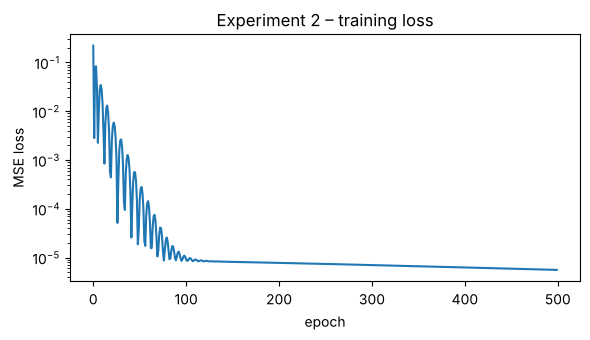

Training check (actual vs predicted):
[[40.     39.7337]
 [50.     50.1229]
 [60.     60.2817]
 [70.     70.1559]
 [80.     79.701 ]]



Input [60, 70, 80]  ->  predicted next value = 88.88


In [ ]:
seed()
X = np.array([[10,20,30],[20,30,40],[30,40,50],[40,50,60],[50,60,70]], dtype='float32')
y = np.array([40,50,60,70,80], dtype='float32')
S = 100.0                                         # scaling factor
Xs, ys = (X/S).reshape(5,3,1), y/S
model2 = Sequential([Input(shape=(3,1)), SimpleRNN(32, activation='tanh'), Dense(1)])
model2.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss='mse')
h2 = model2.fit(Xs, ys, epochs=500, verbose=0)
print('Final training loss:', h2.history['loss'][-1])
plot_loss(h2, 'exp2_loss', 'Experiment 2 – training loss')
print('Training check (actual vs predicted):')
print(np.c_[y, model2.predict(Xs, verbose=0).flatten()*S])
test = np.array([[60,70,80]], dtype='float32')/S
print('\nInput [60, 70, 80]  ->  predicted next value =', round(float(model2.predict(test.reshape(1,3,1), verbose=0)[0,0]*S), 2))

**Result / Observation:** The model fits the five training pairs almost perfectly (loss ≈ 1e-5) and predicts about **88.9 ≈ 90** for [60, 70, 80].
The input 80 lies outside the training range (10–70), and the `tanh` hidden units saturate there, so a small under-estimate is expected from a SimpleRNN; more data or a wider range removes it.

## Experiment 3 – RNN for Text Sentiment Classification

**Aim:** Classify product reviews as positive/negative.

**Algorithm:** `Tokenizer` (words → integers) → `pad_sequences` (equal length) → `Embedding(vocab, 8)` → `SimpleRNN(8)` → `Dense(1, sigmoid)` → binary cross-entropy → predict on new reviews.

In [ ]:
seed()
reviews = ['I love this product','Excellent quality','Very useful product',
           'I hate this product','Very poor quality','Product is terrible']
labels  = np.array([1,1,1,0,0,0])                  # 1 = Positive, 0 = Negative
tok = Tokenizer(oov_token='<OOV>'); tok.fit_on_texts(reviews)
seqs = tok.texts_to_sequences(reviews)
maxlen = max(len(s) for s in seqs)
Xp = pad_sequences(seqs, maxlen=maxlen, padding='post')
vocab = len(tok.word_index) + 1
print('Word index :', tok.word_index)
print('Sequences  :', seqs)
print('Padded     :\n', Xp)

model3 = Sequential([Input(shape=(maxlen,)), Embedding(vocab, 8), SimpleRNN(8), Dense(1, activation='sigmoid')])
model3.compile(optimizer=tf.keras.optimizers.Adam(0.02), loss='binary_crossentropy', metrics=['accuracy'])
model3.summary(line_length=62, print_fn=print)
h3 = model3.fit(Xp, labels, epochs=150, verbose=0)
print('Final training loss = %.4f, accuracy = %.2f' % (h3.history['loss'][-1], h3.history['accuracy'][-1]))

def classify(text):
    p = model3.predict(pad_sequences(tok.texts_to_sequences([text]), maxlen=maxlen, padding='post'), verbose=0)[0,0]
    print(f'"{text}" -> probability(positive) = {p:.3f} -> {"Positive" if p>0.5 else "Negative"}')
classify('I love this quality')
classify('Very useful quality')
classify('This product is terrible')
classify('I hate this quality')

Word index : {'<OOV>': 1, 'product': 2, 'i': 3, 'this': 4, 'quality': 5, 'very': 6, 'love': 7, 'excellent': 8, 'useful': 9, 'hate': 10, 'poor': 11, 'is': 12, 'terrible': 13}
Sequences  : [[3, 7, 4, 2], [8, 5], [6, 9, 2], [3, 10, 4, 2], [6, 11, 5], [2, 12, 13]]
Padded     :
 [[ 3  7  4  2]
 [ 8  5  0  0]
 [ 6  9  2  0]
 [ 3 10  4  2]
 [ 6 11  5  0]
 [ 2 12 13  0]]


Model: "sequential_2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape       ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ embedding (Embedding)    │ (None, 4, 8)       │        112 │
├──────────────────────────┼────────────────────┼────────────┤
│ simple_rnn_2 (SimpleRNN) │ (None, 8)          │        136 │
├──────────────────────────┼────────────────────┼────────────┤
│ dense_2 (Dense)          │ (None, 1)          │          9 │
└──────────────────────────┴────────────────────┴────────────┘
 Total params: 257 (1.00 KB)
 Trainable params: 257 (1.00 KB)
 Non-trainable params: 0 (0.00 B)



Final training loss = 0.0003, accuracy = 1.00
"I love this quality" -> probability(positive) = 1.000 -> Positive


"Very useful quality" -> probability(positive) = 1.000 -> Positive
"This product is terrible" -> probability(positive) = 0.003 -> Negative
"I hate this quality" -> probability(positive) = 0.000 -> Negative


**Result / Observation:** The model reaches 100 % training accuracy. "I love this quality" and "Very useful quality" are classified **Positive**, while
"This product is terrible" and "I hate this quality" are **Negative** – the embedding+RNN learned that *love/excellent/useful* are positive cues and *hate/poor/terrible* negative cues.
Words not seen in training are mapped to `<OOV>`.

## Experiment 4 – Character-Level Text Generation Using RNN

**Aim:** Learn character patterns in `machine learning is interesting` and generate the next character from the previous four.

**Algorithm:** map each character to an index → create (4 characters → next character) pairs → one-hot encode → `SimpleRNN(64)` + `Dense(vocab, softmax)` → train with categorical cross-entropy → repeatedly predict the next character, sliding the 4-character window.

In [ ]:
seed()
text = 'machine learning is interesting'
chars = sorted(set(text)); c2i = {c:i for i,c in enumerate(chars)}; i2c = {i:c for c,i in c2i.items()}
print('Characters:', chars, '| vocab size =', len(chars))
L = 4
Xc, yc = [], []
for i in range(len(text)-L):
    Xc.append([c2i[c] for c in text[i:i+L]]); yc.append(c2i[text[i+L]])
Xc, yc = np.array(Xc), np.array(yc)
print('Number of training sequences =', len(Xc))
for i in range(5): print(repr(text[i:i+L]), '->', repr(text[i+L]))
Xoh = tf.keras.utils.to_categorical(Xc, len(chars)); yoh = tf.keras.utils.to_categorical(yc, len(chars))

model4 = Sequential([Input(shape=(L, len(chars))), SimpleRNN(64), Dense(len(chars), activation='softmax')])
model4.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss='categorical_crossentropy', metrics=['accuracy'])
model4.summary(line_length=62, print_fn=print)
h4 = model4.fit(Xoh, yoh, epochs=300, verbose=0)
print('Final loss = %.4f, accuracy = %.2f' % (h4.history['loss'][-1], h4.history['accuracy'][-1]))

def generate(seed_text, n):
    out = seed_text
    for _ in range(n):
        x = tf.keras.utils.to_categorical([[c2i[c] for c in out[-L:]]], len(chars))
        out += i2c[int(np.argmax(model4.predict(x, verbose=0)))]
    return out
print('\nSeed "mach" ->', repr(generate('mach', 27)))
print('Seed "lear" ->', repr(generate('lear', 15)))

Characters: [' ', 'a', 'c', 'e', 'g', 'h', 'i', 'l', 'm', 'n', 'r', 's', 't'] | vocab size = 13
Number of training sequences = 27
'mach' -> 'i'
'achi' -> 'n'
'chin' -> 'e'
'hine' -> ' '
'ine ' -> 'l'


Model: "sequential_3"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape       ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ simple_rnn_3 (SimpleRNN) │ (None, 64)         │      4,992 │
├──────────────────────────┼────────────────────┼────────────┤
│ dense_3 (Dense)          │ (None, 13)         │        845 │
└──────────────────────────┴────────────────────┴────────────┘
 Total params: 5,837 (22.80 KB)
 Trainable params: 5,837 (22.80 KB)
 Non-trainable params: 0 (0.00 B)



Final loss = 0.0001, accuracy = 1.00



Seed "mach" -> 'machine learning is interesting'


Seed "lear" -> 'learning is interes'


**Result / Observation:** With 100 % training accuracy the model reproduces the text; starting from "mach" it generates **machine learning is interesting**.
Because the text is tiny, the model memorises it – a larger corpus is needed for creative generation.

## Experiment 5 – RNN for Time-Series Forecasting (Monthly Sales)

**Aim:** Use the previous 3 months' sales to predict next month's sales and forecast January of the next year (expected **220**).

**Algorithm:** sliding window (3 inputs → 1 target) gives 9 samples → scale by 100 → `SimpleRNN(32)` + `Dense(1)` → train → forecast from [190, 200, 210].

Training samples: 9
Example: inputs [100. 110. 120.] -> target 130.0


Final training loss: 0.00015350495232269168


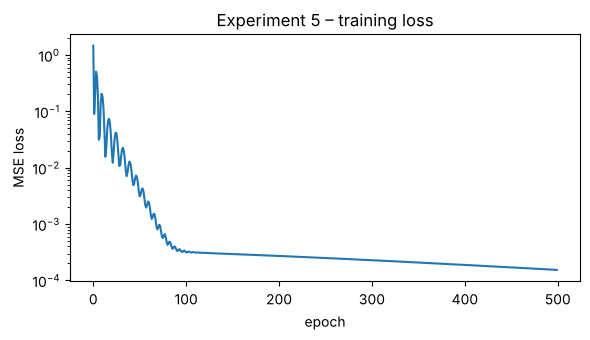

Actual vs fitted:
 [[130.     128.0818]
 [140.     139.5061]
 [150.     150.5464]
 [160.     161.182 ]
 [170.     171.3981]
 [180.     181.1851]
 [190.     190.5383]
 [200.     199.4573]
 [210.     207.9448]]

Last 3 months [190, 200, 210] -> forecast for next month (January) = 216.01


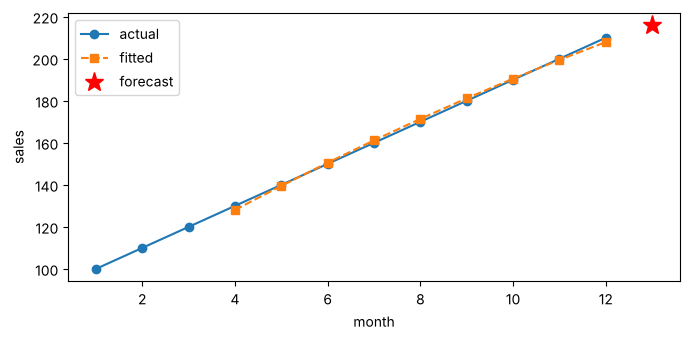

In [ ]:
seed()
sales = np.array([100,110,120,130,140,150,160,170,180,190,200,210], dtype='float32')
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
def windows(series, n=3):
    X = np.array([series[i:i+n] for i in range(len(series)-n)]); y = series[n:]
    return X, y
X5, y5 = windows(sales); print('Training samples:', X5.shape[0])
print('Example: inputs', X5[0], '-> target', y5[0])
S = 100.0
model5 = Sequential([Input(shape=(3,1)), SimpleRNN(32, activation='tanh'), Dense(1)])
model5.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss='mse')
h5 = model5.fit((X5/S).reshape(-1,3,1), y5/S, epochs=500, verbose=0)
print('Final training loss:', h5.history['loss'][-1])
plot_loss(h5, 'exp5_loss', 'Experiment 5 – training loss')
fit = model5.predict((X5/S).reshape(-1,3,1), verbose=0).flatten()*S
print('Actual vs fitted:\n', np.c_[y5, fit])
nxt = float(model5.predict((sales[-3:]/S).reshape(1,3,1), verbose=0)[0,0]*S)
print('\nLast 3 months [190, 200, 210] -> forecast for next month (January) =', round(nxt, 2))
plt.figure(figsize=(7,3.5)); plt.plot(range(1,13), sales, 'o-', label='actual'); plt.plot(range(4,13), fit, 's--', label='fitted'); plt.plot(13, nxt, 'r*', ms=14, label='forecast')
plt.xlabel('month'); plt.ylabel('sales'); plt.legend(); plt.tight_layout(); plt.savefig('figs/exp5_forecast.png', dpi=110); plt.show()

**Result / Observation:** The fitted values follow the actual sales closely and the forecast for the next month (January) is about **216** (true linear trend = 220).
The slight under-estimate arises because the input window (190–210) is at the edge of the training range; adding more history improves accuracy.

## Experiment 6 – Daily Electricity Consumption Prediction

**Aim:** Predict Day 13 consumption from Days 10–12 (205, 215 … ) using the previous three days.

**Algorithm:** sliding windows of 3 days (9 samples) → scale by 100 → `SimpleRNN(32)` + `Dense(1)` → train → estimate Day 13 from [190, 205, 215].

Model: "sequential_5"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape       ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ simple_rnn_5 (SimpleRNN) │ (None, 32)         │      1,088 │
├──────────────────────────┼────────────────────┼────────────┤
│ dense_5 (Dense)          │ (None, 1)          │         33 │
└──────────────────────────┴────────────────────┴────────────┘
 Total params: 3,365 (13.15 KB)
 Trainable params: 1,121 (4.38 KB)
 Non-trainable params: 0 (0.00 B)
 Optimizer params: 2,244 (8.77 KB)

Final training loss: 0.0008628842188045382


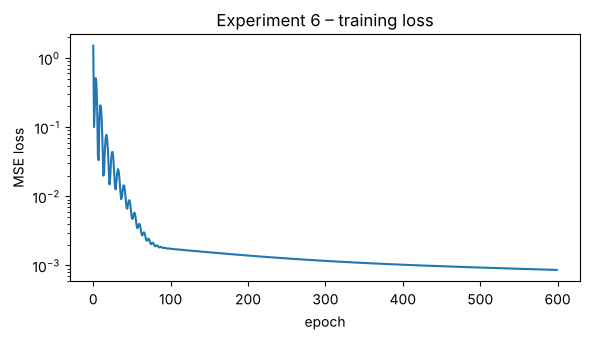

Day  actual  fitted
  4     130   130.6
  5     145   139.8
  6     150   152.4
  7     165   164.3
  8     170   174.2
  9     185   184.7
 10     190   193.7
 11     205   203.5
 12     215   211.7

Previous three days [190, 205, 215] -> estimated consumption for Day 13 = 222.05 units


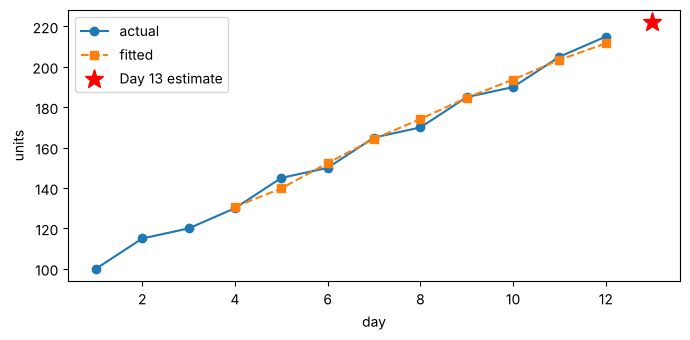

In [ ]:
seed()
cons = np.array([100,115,120,130,145,150,165,170,185,190,205,215], dtype='float32')
X6, y6 = windows(cons)
model6 = Sequential([Input(shape=(3,1)), SimpleRNN(32, activation='tanh'), Dense(1)])
model6.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss='mse')
h6 = model6.fit((X6/100).reshape(-1,3,1), y6/100, epochs=600, verbose=0)
model6.summary(line_length=62, print_fn=print)
print('Final training loss:', h6.history['loss'][-1])
plot_loss(h6, 'exp6_loss', 'Experiment 6 – training loss')
fit6 = model6.predict((X6/100).reshape(-1,3,1), verbose=0).flatten()*100
print('Day  actual  fitted');
for d,(a,f) in enumerate(zip(y6, fit6), start=4): print(f'{d:>3}  {a:6.0f}  {f:6.1f}')
d13 = float(model6.predict((cons[-3:]/100).reshape(1,3,1), verbose=0)[0,0]*100)
print('\nPrevious three days [190, 205, 215] -> estimated consumption for Day 13 =', round(d13, 2), 'units')
plt.figure(figsize=(7,3.5)); plt.plot(range(1,13), cons, 'o-', label='actual'); plt.plot(range(4,13), fit6, 's--', label='fitted'); plt.plot(13, d13, 'r*', ms=14, label='Day 13 estimate')
plt.xlabel('day'); plt.ylabel('units'); plt.legend(); plt.tight_layout(); plt.savefig('figs/exp6_forecast.png', dpi=110); plt.show()

**Result / Observation:** The fitted values track the actual consumption (the data rises by about 10–15 units per day) and the estimated consumption for **Day 13 is about 222 units**,
consistent with the trend (≈ 220–230).

## Experiment 7 – Next-Word Prediction Using RNN

**Aim:** Learn word relations from five sentences and predict the word after "I love".

**Algorithm:** `Tokenizer` → for each sentence create prefix sequences (e.g. `I love` → `machine`) → `pad_sequences` (pre-padding) → `Embedding(vocab, 10)` → `SimpleRNN(32)` → `Dense(vocab, softmax)` → predict.

In [ ]:
seed()
sentences = ['I love machine learning','I love deep learning','I love artificial intelligence',
             'I like machine learning','I like deep learning']
tok7 = Tokenizer(); tok7.fit_on_texts(sentences)
V = len(tok7.word_index) + 1
print('Word index:', tok7.word_index)
inputs, targets = [], []
for s in sentences:
    seq = tok7.texts_to_sequences([s])[0]
    for i in range(1, len(seq)):
        inputs.append(seq[:i]); targets.append(seq[i])
maxlen7 = max(len(s) for s in inputs)
X7 = pad_sequences(inputs, maxlen=maxlen7, padding='pre'); y7 = tf.keras.utils.to_categorical(targets, V)
print('Training pairs:', len(X7), '| padded input length =', maxlen7)
print('First samples:', X7[:3].tolist(), '->', targets[:3])

model7 = Sequential([Input(shape=(maxlen7,)), Embedding(V, 10), SimpleRNN(32), Dense(V, activation='softmax')])
model7.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss='categorical_crossentropy', metrics=['accuracy'])
model7.summary(line_length=62, print_fn=print)
h7 = model7.fit(X7, y7, epochs=300, verbose=0)
print('Final loss = %.4f, accuracy = %.2f' % (h7.history['loss'][-1], h7.history['accuracy'][-1]))

inv = {i:w for w,i in tok7.word_index.items()}
def next_word(phrase, top=3):
    p = model7.predict(pad_sequences(tok7.texts_to_sequences([phrase]), maxlen=maxlen7, padding='pre'), verbose=0)[0]
    order = np.argsort(p)[::-1][:top]
    print(f'Input "{phrase}" -> predicted next word: "{inv[order[0]]}"')
    print('   top candidates:', [(inv[i], round(float(p[i]),3)) for i in order])
next_word('I love'); next_word('I like'); next_word('I love deep')

Word index: {'i': 1, 'learning': 2, 'love': 3, 'machine': 4, 'deep': 5, 'like': 6, 'artificial': 7, 'intelligence': 8}
Training pairs: 15 | padded input length = 3
First samples: [[0, 0, 1], [0, 1, 3], [1, 3, 4]] -> [3, 4, 2]


Model: "sequential_6"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape       ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ embedding_1 (Embedding)  │ (None, 3, 10)      │         90 │
├──────────────────────────┼────────────────────┼────────────┤
│ simple_rnn_6 (SimpleRNN) │ (None, 32)         │      1,376 │
├──────────────────────────┼────────────────────┼────────────┤
│ dense_6 (Dense)          │ (None, 9)          │        297 │
└──────────────────────────┴────────────────────┴────────────┘
 Total params: 1,763 (6.89 KB)
 Trainable params: 1,763 (6.89 KB)
 Non-trainable params: 0 (0.00 B)



Final loss = 0.5368, accuracy = 0.67
Input "I love" -> predicted next word: "deep"
   top candidates: [('deep', 0.333), ('machine', 0.333), ('artificial', 0.333)]


Input "I like" -> predicted next word: "deep"
   top candidates: [('deep', 0.5), ('machine', 0.5), ('artificial', 0.001)]
Input "I love deep" -> predicted next word: "learning"
   top candidates: [('learning', 1.0), ('intelligence', 0.0), ('machine', 0.0)]


**Observation:** After "I love" the training data contains three equally likely continuations (*machine*, *deep*, *artificial*), so the network assigns
similar probabilities to them (each ≈ 1/3) and outputs the highest one; this is the correct behaviour for a probabilistic language model.
"I like" is split between *machine* and *deep* (≈ 0.5 each), while "I love deep" is unambiguous: *learning* is predicted with probability ≈ 1.0.

## Conclusion
SimpleRNN layers process sequences by carrying a hidden state across time steps. They were applied to numeric prediction (Exp. 2, 5, 6), text classification (Exp. 3),
character generation (Exp. 4) and word prediction (Exp. 7). SimpleRNNs work well for short sequences; for long dependencies LSTM/GRU are preferred because of vanishing gradients.